In [23]:
import torch 
import requests
import json
import os 
import sys 
import inspect
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [24]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Selected :", device)

test_tensor = torch.tensor([1.0,2.0], device = device)
result = test_tensor * 2

print("Result:", result)

Selected : mps
Result: tensor([2., 4.], device='mps:0')


===== ARC-AGI-1 =====
{"test": [{"input": [[7, 0, 7], [7, 0, 7], [7, 7, 0]], "output": [[7, 0, 7, 0, 0, 0, 7, 0, 7], [7, 0, 7, 0, 0, 0, 7, 0, 7], [7, 7, 0, 0, 0, 0, 7, 7, 0], [7, 0, 7, 0, 0, 0, 7, 0, 7], [7, 0, 7, 0, 0, 0, 7, 0, 7], [7, 7, 0, 0, 0, 0, 7, 7, 0], [7, 0, 7, 7, 0, 7, 0, 0, 0], [7, 0, 7, 7, 0, 7, 0, 0, 0], [7, 7, 0, 7, 7, 0, 0, 0, 0]]}], "train": [{"input": [[0, 7, 7], [7, 7, 7], [0, 7, 7]], "output": [[0, 0, 0, 0, 7, 7, 0, 7, 7], [0, 0, 0, 7, 7, 7, 7, 7, 7], [0, 0, 0, 0, 7, 7, 0, 7, 7], [0, 7, 7, 0, 7, 7, 0, 7, 7], [7, 7, 7, 7, 7, 7, 7, 7, 7], [0, 7, 7, 0, 7, 7, 0, 7, 7], [0, 0, 0, 0, 7, 7, 0, 7, 7], [0, 0, 0, 7, 7, 7, 7, 7, 7], [0, 0, 0, 0, 7, 7, 0, 7, 7]]}, {"input": [[4, 0, 4], [0, 0, 0], [0, 4, 0]], "output": [[4, 0, 4, 0, 0, 0, 4, 0, 4], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 4, 0, 0, 0, 0, 0, 4, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 4, 0, 4, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 4, 0, 0, 0, 0]]}, 

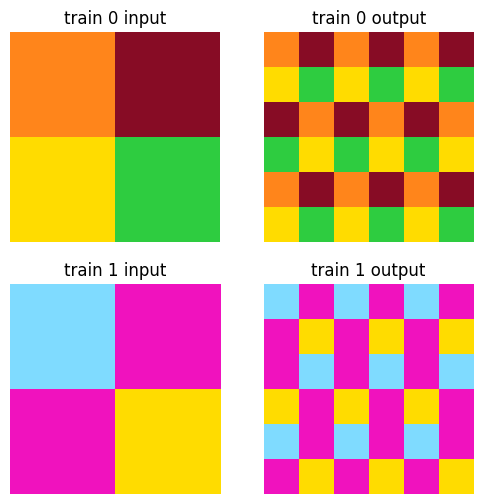

In [25]:


if os.path.exists('arc_data.json'):
    data = json.load(open('arc_data.json'))
else:
    data = {}
    for name, repo in {'ARC-AGI-1': 'fchollet/ARC-AGI', 'ARC-AGI-2': 'arcprize/ARC-AGI-2'}.items():
        files = requests.get(f'https://api.github.com/repos/{repo}/contents/data/training').json()
        data[name] = [requests.get(f['download_url']).json() for f in files]
    json.dump(data, open('arc_data.json', 'w'))

for name, puzzles in data.items():
    print(f'===== {name} =====')
    for puzzle in puzzles[:5]:
        print(json.dumps(puzzle))




colors = ListedColormap(['#000000', '#0074D9', '#FF4136', '#2ECC40', '#FFDC00',
                         '#AAAAAA', '#F012BE', '#FF851B', '#7FDBFF', '#870C25'])

puzzle = data['ARC-AGI-2'][0]
pairs = puzzle['train']

fig, axes = plt.subplots(len(pairs), 2, figsize=(6, 3 * len(pairs)), squeeze=False)
for i, pair in enumerate(pairs):
    for j, key in enumerate(['input', 'output']):
        axes[i][j].imshow(pair[key], cmap=colors, vmin=0, vmax=9)
        axes[i][j].set_title(f'train {i} {key}')
        axes[i][j].axis('off')
plt.show()

In [26]:
source_folder = "/Users/kostas/dev/python/ptch/TinyRecursiveModels"
sys.path.insert(0, source_folder)

from models.recursive_reasoning.trm import TinyRecursiveReasoningModel_ACTV1 as TRM

print(TRM.__name__)

TinyRecursiveReasoningModel_ACTV1


In [27]:

from models.recursive_reasoning.trm import TinyRecursiveReasoningModel_ACTV1Config

print(inspect.getsource(TinyRecursiveReasoningModel_ACTV1Config))

class TinyRecursiveReasoningModel_ACTV1Config(BaseModel):
    batch_size: int
    seq_len: int
    puzzle_emb_ndim: int = 0
    num_puzzle_identifiers: int
    vocab_size: int

    H_cycles: int
    L_cycles: int

    H_layers: int # ignored
    L_layers: int

    # Transformer config
    hidden_size: int
    expansion: float
    num_heads: int
    pos_encodings: str

    rms_norm_eps: float = 1e-5
    rope_theta: float = 10000.0
    
    # Halting Q-learning config
    halt_max_steps: int
    halt_exploration_prob: float

    forward_dtype: str = "bfloat16"

    # Alexia: added
    mlp_t: bool = False # use mlp on L instead of transformer
    puzzle_emb_len: int = 16 # if non-zero, its specified to this value
    no_ACT_continue: bool =  True # No continue ACT loss, only use the sigmoid of the halt which makes much more sense



In [28]:


config = {

    "batch_size" : 1, 
    "seq_len": 900,
    "vocab_size" : 12,
    "hidden_size" : 512,
    "num_heads" : 8,
    "expansion" : 4,
    "L_layers" :2,
    "H_layers":0 ,
    "H_cycles": 3,
    "L_cycles": 4,
    "num_puzzle_identifiers": 1,
    "puzzle_emb_ndim": 512,
    "puzzle_emb_len": 16,
    "pos_encodings": "rope",
    "forward_dtype": "float32",
    "halt_max_steps": 16,
    "halt_exploration_prob": 0.1,

}

model = TRM(config)
param_count = sum(p.numel() for p in model.parameters())
print(f"Model {TRM.__name__} has {param_count} parameters.")



Model TinyRecursiveReasoningModel_ACTV1 has 6829058 parameters.


In [ ]:

with open("/Users/kostas/dev/python/ptch/arc_data.json", encoding="utf-8") as file:
    data = json.load(file)

puzzle = data["ARC-AGI-2"][0]
input_grid = torch.tensor(puzzle["train"][0]["input"], dtype=torch.long)

height, width = input_grid.shape

token_grid = torch.zeros((30, 30), dtype=torch.long)
token_grid[:height, :width] = input_grid + 2

if height < 30:
    token_grid[height, :width] = 1

if width < 30:
    token_grid[:height, width] = 1

input_tokens = token_grid.reshape(1, 900)

print("Original grid shape:", input_grid.shape)
print("Model input shape:", input_tokens.shape)

puzzle_identifires = torch.zeros((1, ), dtype = torch.long)
batch = {
    "inputs": input_tokens,
    "puzzle_identifiers": puzzle_identifires
}


print("Batch input_tokens shape:", batch["inputs"].shape)
print("Batch puzzle_identifiers shape:", batch["puzzle_identifiers"].shape)



Original grid shape: torch.Size([2, 2])
Model input shape: torch.Size([1, 900])


KeyError: 'input_tokens'

In [30]:
'''for _ in range(refinement_rounds):
    for _ in range(reasoning_steps):
        z = reasoning_network(x + y + z)

    y = reasoning_network(y + z)

scores = output_head(y)'''
carry = model.initial_carry(batch)

print("Answer state shape:", carry.inner_carry.z_H.shape)
print("Working state shape:", carry.inner_carry.z_L.shape)






KeyError: 'inputs'

In [ ]:

print("Buffer available:", hasattr(torch.nn, "Buffer"))

Buffer available: True
